In [1]:
import xarray as xr
import numpy as np
import dask
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import pathlib
import os
import intake
import easygems.healpix as egh
import global3d_track as g3d

In [159]:
# data
tobac_dir = pathlib.Path('/work/bb1153/b382635/data/final_tracks/tbc_frozen_1e4/tropics')
track_dir = pathlib.Path('/work/bb1153/b382635/data/final_tracks/dcc_frozen_1e4/tropics')

# save
paperdir = pathlib.Path('/work/bb1153/b382635/plots/model_paper/grl_resubmission/figures/supplementary')
savedir = pathlib.Path('/work/bb1153/b382635/plots/model_paper/grl_resubmission/figures/track_filtering')
paperdir.mkdir(parents=1, exist_ok=1)
savedir.mkdir(parents=1, exist_ok=1)

dpi = 300
ext = 'pdf'

mpl.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size':         10,
    'axes.labelsize':    10,
    'axes.titlesize':    10,
    'xtick.labelsize':   10,
    'ytick.labelsize':   10,
    'legend.fontsize':   10,
    'lines.linewidth':   0.8,
    'axes.linewidth':    0.6,
    'xtick.major.width': 0.6,
    'ytick.major.width': 0.6,
    'xtick.direction':   'in',
    'ytick.direction':   'in',
})

### LOAD TRACKING

In [3]:
days = ('20210701','20210702','20210703','20210704')
di = g3d.utils.tools.load_linked_records(track_dir, days, tbcdir=None)
updrafts, clouds, dcc_times = di['w'], di['cld'], di['df']

In [4]:
print(dcc_times.dcc.nunique(), 'DCCs tracked')

10206 DCCs tracked


### FILTER

#### FILTER TRACK QUALITY

In [106]:
# 1. DCC lifetime < 1 hour

def get_duration(d):
    return (d.max() - d.min()).total_seconds() / (60*60) + 0.25 # hours

df = pd.DataFrame()
df['lifetime'] = dcc_times.where(dcc_times.dcc>0)[['time','dcc']].groupby('dcc')['time'].apply(get_duration)

In [107]:
# 2. ensure that the track starts with a convective core

first_updraft = updrafts.groupby('dcc').time.min()
first_anvil = clouds.groupby('dcc').time.min()
inital_detections = pd.concat([first_updraft, first_anvil], axis=1, keys=['updraft', 'anvil'])
t_before_anvil = pd.to_timedelta(inital_detections.anvil - inital_detections.updraft)
t_before_anvil = t_before_anvil.dt.total_seconds() / 60 # to minutes

df['mins_before_anvil'] = t_before_anvil

In [108]:
# 3. ensure core initiated below the freezing level

initial_updrafts = updrafts.where(updrafts.time_cell == pd.Timedelta(0)).dropna()
initial_zcentre = initial_updrafts.groupby('dcc')['height'].max() # take lowest model level (higher is close to the surface) where there were multiple

df['initial_core_model_level'] = initial_zcentre

In [109]:
# 4 - avoid the domain boundary

boundary_lat = 15
closest_dist = clouds.groupby('dcc')['latitude'].apply(lambda x: boundary_lat - np.min(np.abs(x))) # get distance at closest points

df['distance_boundary'] = closest_dist

In [110]:
# apply rules

df['too_short'] = df.lifetime < 1
df['anvil_first'] = df.mins_before_anvil < 0
df['too_high'] = df.initial_core_model_level <= 62
df['too_close'] = df.distance_boundary <= 1

count_fails = df[['too_short','anvil_first','too_high','too_close']].sum(axis=1)
df['invalid'] = count_fails > 0

# decisions['valid_but_complex_convection'] = np.logical_and(count_fails==0, decisions.complex_convection)
# decisions['valid'] = np.logical_and(count_fails==0, ~decisions.complex_convection)

df[['too_short','anvil_first','too_high','too_close','invalid']].sum(axis=0)

too_short       212
anvil_first    2760
too_high        455
too_close       514
invalid        3407
dtype: int64

#### VIEW FILTERING RESULTS

In [127]:
c = plt.get_cmap('Greys')(.6)
lparams = dict(ls='--', c=plt.get_cmap('Reds')(.8), lw=1.5)

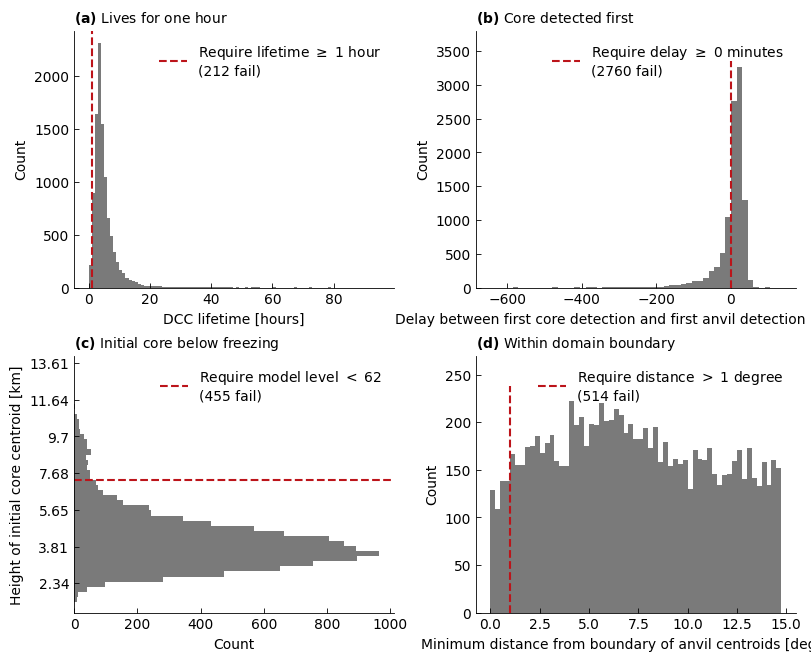

In [163]:
fig, axs = plt.subplots(2, 2, figsize=(8,6.5), layout='constrained')
axs = axs.flat

ax = axs[0]
ax.axvline(1, label=f'Require lifetime $\geq$ 1 hour\n({df.too_short.sum()} fail)', **lparams)
ax.hist(df.lifetime, bins=np.arange(0, df.lifetime.max(), 1), fc=c, histtype='stepfilled')
ax.set_ylabel('Count')
ax.set_xlabel('DCC lifetime [hours]')

ax = axs[1]
ax.axvline(0, ymax=.88, label=f'Require delay $\geq$ 0 minutes\n({df.anvil_first.sum()} fail)', **lparams)
ax.hist(df.mins_before_anvil, bins=np.arange(df.mins_before_anvil.min(), df.mins_before_anvil.max(), 15), fc=c, histtype='stepfilled')
ax.set_ylabel('Count')
ax.set_xlabel('Delay between first core detection and first anvil detection [minutes]')
ax.set_ylim(0,3800)

ax = axs[2]
cat = intake.open_catalog("https://data.nextgems-h2020.eu/catalog.yaml")
ds = cat.ICON.ngc4008a(time="PT15M", zoom=9).to_dask().isel(time=0).pipe(egh.attach_coords)['zg']
def cells_of_domain(ds):
    lon_min, lon_max, lat_min, lat_max = (0, 360, -15, 15)
    extent_mask = (ds["lon"] > lon_min) & (ds["lon"] < lon_max) & (ds["lat"] > lat_min) & (ds["lat"] < lat_max)
    return np.where(extent_mask)[0]
zg = ds.sel(cell=cells_of_domain(ds)).mean('cell') / 1000
bins = zg.level_full.values
ax.axhline(62, label=f'Require model level $<$ 62\n({df.too_high.sum()} fail)', **lparams)
ax.hist(df.initial_core_model_level, bins=50, fc=c, orientation='horizontal', histtype='stepfilled')
ax.set_yticks(bins[::5])
ax.set_yticklabels(zg.sel(level_full=bins).values.round(2)[::5])
ax.set_ylabel('Height of initial core centroid [km]')
ax.set_xlabel('Count', fontsize=fs)
ax.set(ylim=(45, 80))
ax.invert_yaxis()

ax = axs[3]
ax.hist(df.distance_boundary, bins=np.arange(0, df.distance_boundary.max(), .25), fc=c, histtype='stepfilled')
ax.set_xlabel('Minimum distance from boundary of anvil centroids [degrees]')
ax.set_ylabel('Count', fontsize=fs)
ax.axvline(1, ymax=.88, label=f'Require distance $>$ 1 degree\n({df.too_close.sum()} fail)', **lparams)
ax.set_ylim(0,270)

axs[0].set_title(r'$\bf{(a)}$ Lives for one hour', loc='left')
axs[1].set_title(r'$\bf{(b)}$ Core detected first', loc='left')
axs[2].set_title(r'$\bf{(c)}$ Initial core below freezing', loc='left')
axs[3].set_title(r'$\bf{(d)}$ Within domain boundary', loc='left')

for i, ax in enumerate(axs):
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper right', frameon=False)

fig.savefig(savedir / f'track_filtering_results.jpg', bbox_inches='tight')
fig.savefig(paperdir / f'track_filtering_results.{ext}', dpi=dpi, bbox_inches='tight')

#### DESIGNATE AS ISOlATED/COMPLEX CONVECTION

Here we define 'isolated' DCCs as those which had relatively simple convective lifecycles. Specifically, we designate a DCCas 'isolated' if there was little or no gap between the first and last convective cores. That nessessitates that the convection tended to happen all at once, which predominantly occurs in systems with few convective cores.

In [31]:
def conv_offset(df):
    group_time = df.groupby('updraft')['time']
    return group_time.min().max() - group_time.max().min()

def duration_first_core(d):
    updraft_start_times = d[d.updraft>0].groupby('updraft').time.min()
    inital_updrafts = updraft_start_times.index[updraft_start_times==updraft_start_times.min()]
    return get_duration(d[d.updraft.isin(inital_updrafts)].time)

# calculate the number of time steps between the first core ending and the last core starting
offsets = updrafts.groupby('dcc')[['updraft','time']].apply(conv_offset)
offset_mins = (pd.to_timedelta(offsets).dt.total_seconds() / 60)
df_working = offset_mins.to_frame('offset') # minutes

# calculate related properties
df_working['duration_first_core'] = updrafts.groupby('dcc')[['updraft','time']].apply(duration_first_core)
df_working['lifetime'] = dcc_times.where(dcc_times.dcc>0)[['time','dcc']].groupby('dcc')['time'].apply(get_duration)

# apply rule: if the duration of the first core was less than 1/4 of total cloud lifetime, allow a delay between first and last of 1/8 of total cloud lifetime
short_first_core = df_working.duration_first_core < 0.25 * df_working.lifetime
df_working['allowed_delay'] = (0.125 * df_working.lifetime * 60) * short_first_core # 0 or proportional to lifecycle characteristics

# if the last core started after the fist one ended, call it invalid
complicated_core_timing = df_working.offset > df_working.allowed_delay
print(complicated_core_timing.sum(), 'had complicated core timing')

3156 had complicated core timing


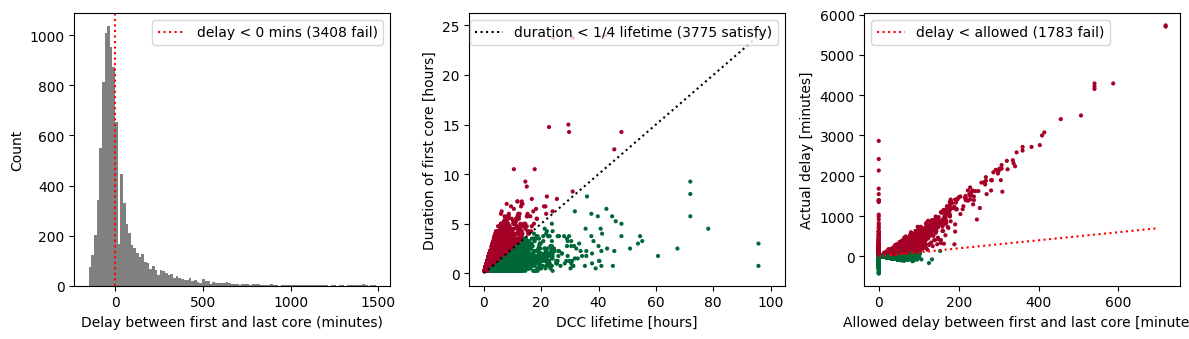

In [32]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5), layout='tight')

ax = axs[0]
bins = np.arange(-10*15, 100*15, 15)
ax.hist(df_working.offset, bins=bins, fc='grey')
ax.axvline(0, label=f"delay < 0 mins ({(df_working.offset>0).sum()} fail)", **lparams)
ax.set(xlabel='Delay between first and last core (minutes)', title='', ylabel='Count')
ax.legend()
 
ax = axs[1]
x, y = df_working.lifetime, df_working.duration_first_core
ax.scatter(x, y, c=y<0.25*x, cmap='RdYlGn', ec='none', marker='.')
x = np.linspace(0,100,100)
ax.plot(x, 0.25 * x, label=f'duration < 1/4 lifetime ({short_first_core.sum()} satisfy)', ls=':', c='k')
ax.set(xlabel='DCC lifetime [hours]', ylabel='Duration of first core [hours]')
ax.legend()

ax = axs[2]
x, y = df_working.allowed_delay, df_working.offset
ax.scatter(x, y, c=y<x, cmap='RdYlGn', ec='none', marker='.')
x0 = np.linspace(0,700,100)
ax.plot(x0, x0, label=f'delay < allowed ({((x>y)*short_first_core).sum()} fail)', **lparams)
ax.set(xlabel='Allowed delay between first and last core [minutes]', ylabel='Actual delay [minutes]')
ax.legend()

fig.savefig(savedir / 'filter_by_simplicity_of_convection.jpg', bbox_inches='tight')


In [33]:
df['valid'] = np.logical_and(~df.invalid, ~complicated_core_timing)
df['valid_but_complex_convection'] = np.logical_and(~df.invalid, complicated_core_timing)

df[['valid','valid_but_complex_convection']].sum(axis=0)

valid                           4600
valid_but_complex_convection    2198
dtype: object

In [34]:
validity = df.copy()

print('total valid', validity[['valid','valid_but_complex_convection']].sum().sum())

total valid 6798


In [35]:
validity

,lifetime,mins_before_anvil,initial_core_model_level,distance_boundary,too_short,anvil_first,too_high,too_close,invalid,valid,valid_but_complex_convection
dcc,,,,,,,,,,,
1.0,95.75,0.0,76.798497,12.057269,False,False,False,False,False,False,True
2.0,24.00,0.0,78.159821,14.949618,False,False,False,False,False,False,True
3.0,7.50,0.0,71.357992,7.417151,False,False,False,False,False,False,True
4.0,11.00,0.0,72.952540,8.089149,False,False,False,False,False,False,True
5.0,5.50,0.0,73.648106,11.074965,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...
67903.0,7.00,15.0,72.254744,1.940739,False,False,False,False,False,False,True
67907.0,5.25,15.0,72.179481,0.977647,False,False,False,True,True,False,False
67917.0,6.75,15.0,75.045726,11.934724,False,False,False,False,False,True,False


### TRACK STATS

#### DERIVE

In [36]:
df = pd.DataFrame(index=validity.index)

In [37]:
# 1 - lifetimes
df['lifetime'] = dcc_times[['time','dcc']].groupby('dcc')['time'].apply(get_duration)

In [38]:
# 2 - number of cores per DCC
df['ncores'] = updrafts[['updraft','dcc']].groupby('dcc')['updraft'].nunique()

In [39]:
# 3 - associate to key regions
di = {"global": (-180,180,-15,15),
      "amazon": (-83, -43, -15, 15),
      "congo": (1, 41, -15, 15),
      "warm_pool": (90, 160, -15, 15)
     }
regions = di.keys()
for r in di.keys():
    longitudes = (di[r][0], di[r][1])
    within = lambda x: np.logical_and(x>longitudes[0], x<longitudes[1]).any()
    df[r] = clouds.groupby('dcc')['longitude'].apply(within)

In [41]:
# 4 - time of initiation
df['initial_time'] = dcc_times.groupby('dcc')['time'].min().astype(str)
df["initial_time"] = pd.to_datetime(df["initial_time"])

# 5 - lifetime of convection
df['duration_convection'] = updrafts.groupby('dcc')['time'].apply(get_duration)

In [42]:
# 6 - inital latitude and longitude
def initial_data(d):
    return d.sort_values('time').iloc[0]
initial_data = updrafts.groupby('dcc')[['latitude','longitude','time']].apply(initial_data)
df['initial_lat'] = initial_data.latitude
df['initial_lon'] = initial_data.longitude

# land/ocean
nextgems_catalog = intake.open_catalog("https://data.nextgems-h2020.eu/catalog.yaml")
data = nextgems_catalog.ICON.ngc4008(time="PT3H", zoom=9).to_dask().isel(time=0)
background = g3d.utils.regrid.Regrid('tropics').perform(data[['ocean_fraction_surface']], zoom=9, resolution=0.1).drop_vars('time')
lats = xr.DataArray(df['initial_lat'].values, dims='dcc')
lons = xr.DataArray(df['initial_lon'].values, dims='dcc')
df['ocean_fraction'] = (
    background['ocean_fraction_surface']
    .sel(lat=lats, lon=lons, method='nearest')
    .values          # drop back to numpy so pandas is happy
)

In [43]:
# 7 - total pixels
df['npixels'] = clouds.groupby('dcc')['num'].sum()

In [44]:
# X - add filtering results

df['valid_but_complex_convection'] = validity.valid_but_complex_convection
df['valid'] = validity.valid

In [45]:
df.head()

,lifetime,ncores,global,amazon,congo,warm_pool,initial_time,duration_convection,initial_lat,initial_lon,ocean_fraction,npixels,valid_but_complex_convection,valid
dcc,,,,,,,,,,,,,,
1.0,95.75,137,True,False,False,True,2021-07-01 00:15:00,95.75,-3.679068,144.774295,1.0,32744517,True,False
2.0,24.00,45,True,False,False,False,2021-07-04 00:00:00,24.00,3.062571,-3.032222,1.0,13324126,True,False
3.0,7.50,3,True,False,True,False,2021-07-02 00:00:00,5.50,8.600409,17.759948,0.0,22317,True,False
4.0,11.00,7,True,False,False,True,2021-07-02 00:00:00,7.25,-7.386997,121.550132,1.0,193333,True,False
5.0,5.50,2,True,False,False,True,2021-07-03 00:00:00,3.50,-4.048660,126.455654,1.0,9188,True,False


#### PLOT

In [46]:
good_df = df[np.logical_or(df.valid_but_complex_convection, df.valid)]

In [47]:
# maximum number of cores for one system:

for r in regions:
    count = good_df.where(np.logical_and(good_df.ncores>20, good_df.loc[:,r]==True)).ncores.max()
    print(r, int(count))

global 525
amazon 195
congo 525
warm_pool 148


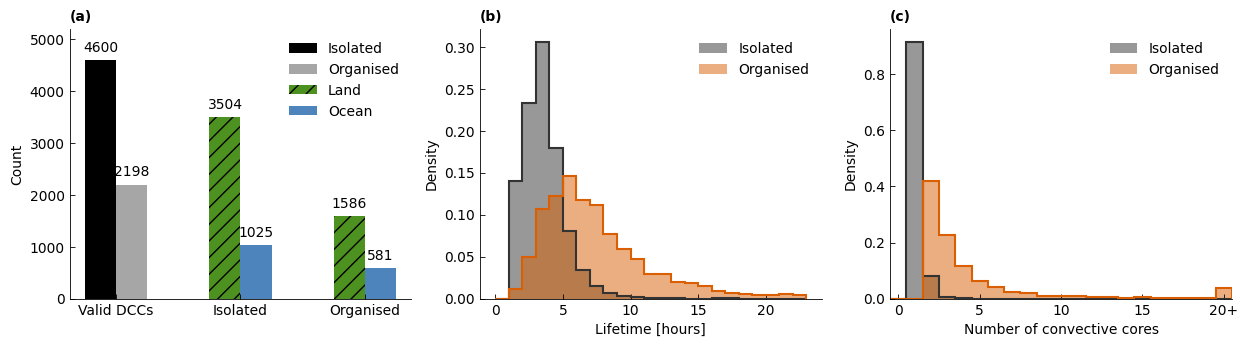

In [161]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
cmap = plt.get_cmap("viridis")
width = 0.25

def label_bar(ax, height, rect):
    ax.annotate(f'{height}',
                xy=(rect[0].get_x() + rect[0].get_width() / 2, height),
                xytext=(0, 4),
                textcoords='offset points',
                ha='center', va='bottom',
                fontsize=fs)

def make_bars(ax, x, left, right, c1='k', c2='k', labl='', labr=''):
    a = 0.35 if c1 == c2 else .8
    left_bar  = ax.bar(x - width / 2, left,  width=width, hatch='//', color=c1, label=labl)
    right_bar = ax.bar(x + width / 2, right, width=width, alpha=a,  color=c2, label=labr)
    label_bar(ax, left,  left_bar)
    label_bar(ax, right, right_bar)

ax = axs[0]
c_land  = '#4d9221'
c_ocean = '#2166ac'
make_bars(ax, 1, good_df.valid.sum(),
                 good_df.valid_but_complex_convection.sum(),
                 'k', 'k', 'Isolated', 'Organised')
make_bars(ax, 2, good_df.valid[good_df.ocean_fraction == 1].sum(),
                 good_df.valid[good_df.ocean_fraction == 0].sum(),
                 c_land, c_ocean, 'Land', 'Ocean')
make_bars(ax, 3, good_df.valid_but_complex_convection[good_df.ocean_fraction == 1].sum(),
                 good_df.valid_but_complex_convection[good_df.ocean_fraction == 0].sum(),
                 c_land, c_ocean, None, None)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['Valid DCCs', 'Isolated', 'Organised'], rotation=0, ha='center', )
ax.tick_params(axis='y', )
ax.set_ylabel("Count",)
ax.set_ylim(None, 5200)
ax.set_title('(a)', loc='left', fontweight='bold')

ax = axs[1]
c1, c2 = '#333333', '#d95f02' 


def make_hist(data, bins, c, lab, params={}):
    ax.hist(data, bins=bins, ec='none', fc=c, label=lab,
            histtype='stepfilled', density=True, alpha=.5, **params)
    ax.hist(data, bins=bins, ec=c, histtype='step', density=True, lw=1.5, **params)

bins = np.arange(0, 24, 1)
make_hist(good_df[good_df.valid].lifetime.dropna(),                         bins, c1, "Isolated")
make_hist(good_df[good_df.valid_but_complex_convection].lifetime.dropna(),  bins, c2, "Organised")
ax.set_xlabel("Lifetime [hours]", )
ax.set_ylabel("Density", )
ax.set_title("(b)", loc='left', fontweight='bold')

ax = axs[2]
overflow = 20
bins = np.arange(0, overflow + 2, 1)
nc_isolated  = good_df[good_df.valid].ncores.dropna().clip(upper=overflow)
nc_organised = good_df[good_df.valid_but_complex_convection].ncores.dropna().clip(upper=overflow)
make_hist(nc_isolated,  bins, c1, "Isolated")
make_hist(nc_organised, bins, c2, "Organised")
tick_vals = np.arange(0, overflow + 1, 5)
ax.set_xticks(tick_vals + 0.5)
ax.set_xticklabels([str(t) if t < overflow else f'{overflow}+' for t in tick_vals])
ax.tick_params(axis='y', )
ax.set_xlim(0, overflow + 1)
ax.set_xlabel("Number of convective cores", )
ax.set_ylabel("Density", )
ax.set_title("(c)", loc='left', fontweight='bold')

for i, ax in enumerate(axs):
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, )

fig.savefig(savedir / f'track_results.jpg', bbox_inches='tight')
fig.savefig(paperdir / f'track_results.{ext}', dpi=dpi, bbox_inches='tight')

#### SAVE

In [104]:
outpath = pathlib.Path(track_dir, 'track_stats')
outpath.mkdir(parents=1, exist_ok=1)

In [40]:
outpath

PosixPath('/work/bb1153/b382635/data/final_tracks/dcc_frozen_1e4/tropics/track_stats')

In [41]:
# validity.to_csv(outpath / 'dcc_validity.csv')

In [42]:
# df.to_csv(outpath / 'dcc_statistics.csv')